<a href="https://colab.research.google.com/github/JonaEmmOfCruz/Machine-learning/blob/main/Hands-on5/Hands_on_5_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1><strong>Linear Classifiers: Support Vector Machines (SVM)</strong></h1>




Las **Support Vector Machines SVM o Máquinas de vectores de soporte** es un algoritmo de aprendizaje supervisado utilizado principalmente para clasificación.

<br>

<h4><strong>Objetivo</strong></h4>

Trazar una frontera o línea divisoria llamada hiperplano entre dos grupos de datos para separarlos correctamente.

<br>

<h4><strong>Diferencia con el Perceptrón</strong></h4>

* **Perceptrón:** Busca cualquier línea que separe las clases, si encuentra una línea que funciona, se detiene ahí, aunque quede pegada a una de las clases lo que la hace muy propensa a fallar con datos nuevos.

* **SVM:** No se conforma con cualquier línea, busca la línea óptima la que quede lo más lejos posible de ambas clases al mismo tiempo.

<br>

<h4><strong>Conceptos claves de SVM</strong></h4>

* **Margen Geometrico:** Es el espacio de seguridad o franja vacía entre las dos clases. SVM busca hacer este margen lo más ancho posible ($2 / \Vert{}w\Vert{}$).

* **Vectores de soporte:** Son los puntos observaciones que están justamente en el borde del margen. Son los puntos más difíciles de clasificar y los únicos que definen la posición de la línea. Si borras todos los demás puntos de la gráfica, el modelo no cambia.

* **Margen Rígido:** Exige que ni un solo punto invada el margen. Solo funciona si los datos son perfectamente separables.

* **Margen Flexible:** Permite que algunos puntos invadan el margen o se equivoquen. La cantidad de permisividad se controla con el parámetro $C$

Donde

* $C$ grande: Modelo estricto busca 0 errores, margen más angosto, riesgo de sobreajuste.

* $C$ pequeño: Modelo tolerante acepta algunos errores a cambio de un margen más ancho y generalizable.

<br>

<h2><strong>Modelo matemático y analítico</strong></h2>

<br>

<h4><strong>Ecuación del Hiperplano</strong></h4>

<br>

$$w^Tx+b=0$$

Donde:

* **Vectores de pesos** <br> $w=[w_1, w_2]:$ <br> Determinan la inclinación o pendiente de la línea

* **Sesgo o bias** <br> $b:$ <br> Desplaza la línea de arriba a abajo o de izquierda a derecha

* $x:$ <br> Son los puntos o características de entrada

<br>

<br>

<h4><strong>Líneas del margen superior e inferior</strong></h4>

<br>

* **Margen de la clase +1: &nbsp; &nbsp;**  $w^T x+b=+1$

* **Margen de la clase -1: &nbsp; &nbsp;**  $w^T x+b=-1$

<br>

<br>

<h4><strong>Regla de decisión</strong></h4>

<br>

$$f(x) = \text{signo}(w^Tx+b)$$

<br>

* Si la ecuacion da $\ge 0$, el modelo predice la Clase 1

* Si la ecuación da $< 0$, el modelo predice la Clase 0.


<h2><strong>Cuadro Comparativo</strong></h2>

|Criterio|Perceptrón|SVM|
|-|-|-|
|**Objetivo**|Encontrar cualquier hiperplano <br> que separe los datos|Encontrar el hiperplano óptimo <br> que maximice el margen|
|**Datos que son necesarios**|Influyen todas las <br> muestras de entrenamiento|Solo le importan los **Vectores de soporte**|
|**Manejo de solapamiento**|Falla o entra en bucle <br> si los datos no son separables|Usa margen flexible $C$ <br> y  variables de holgura|
|**Problemas No Lineales**|No puede resolverlos de <br> manera nativa|Los resuelve fácilmente mediante  <br> el **Truco del kernel**|

<h2><strong>Implementación en Python</strong></h2>

<h3><strong>Importación de librerías</strong></h3>

In [63]:
# Módulo para operaciones matriciales y manejo de arreglos numéricos
import numpy as np

# Módulo para manipulación, estructuración e inspección de datasets en DataFrames
import pandas as pd

# Módulo para la creación de gráficos e iteración visual
import matplotlib.pyplot as plt

# Módulo para aplicar temas estilizados a las gráficas y mapas de calor
import seaborn as sns

# Carga directa del dataset de flores Iris desde Scikit-Learn
from sklearn.datasets import load_iris

# Clase para realizar el escalamiento y estandarización Z-score de las características
from sklearn.preprocessing import StandardScaler

# Función para dividir el dataset en subconjuntos independientes de entrenamiento y prueba
from sklearn.model_selection import train_test_split

# Clase Support Vector Classifier (SVC) de Scikit-Learn
from sklearn.svm import SVC

# Métricas de evaluación para medir el desempeño cuantitativo de clasificación
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Configuración del estilo gráfico global para la sesión de ejecuciones
sns.set_theme(style="whitegrid")

<h3><strong>Recolección y filtrado de datos</strong></h3>

In [64]:
# Cargamos el dataset Iris crudo de la librería
iris_raw = load_iris()

# Lo convertimos a un DataFrame (tabla) para manipularlo cómodamente
df_iris = pd.DataFrame(data=iris_raw.data, columns=iris_raw.feature_names)
df_iris['especie'] = iris_raw.target

# Filtramos para tener solo un problema binario (Clases 0 y 1)
df_binary = df_iris[df_iris['especie'].isin([0, 1])].copy()

# X: Matriz de características (Sepal length, Petal length)
X_raw = df_binary[['sepal length (cm)', 'petal length (cm)']].to_numpy()

# y: Vector de etiquetas (0 = Setosa, 1 = Versicolor)
y = df_binary['especie'].to_numpy()

print(f"Dimensiones de los datos de entrada X: {X_raw.shape}")
print(f"Cantidad de muestras por clase: {np.bincount(y)}")

Dimensiones de los datos de entrada X: (100, 2)
Cantidad de muestras por clase: [50 50]


<h3><strong>Grafica del DataSet</strong></h3>

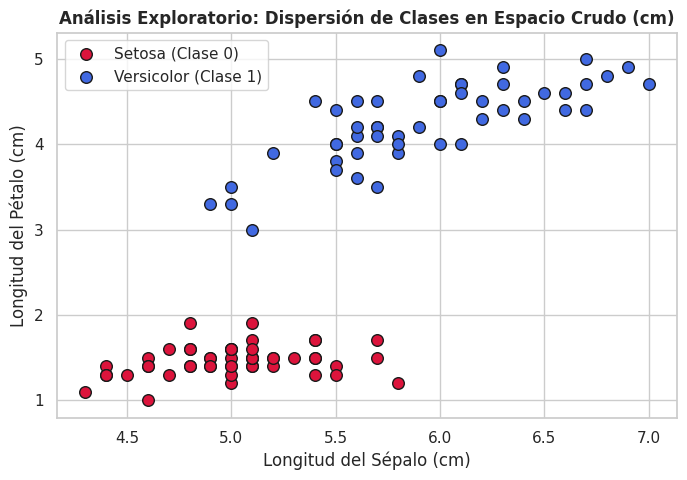

In [65]:
plt.figure(figsize=(8, 5))

# Dibujamos las muestras de la Clase 0 (Setosa) en color rojo
plt.scatter(
    X_raw[y == 0, 0], X_raw[y == 0, 1],
    color='crimson', label='Setosa (Clase 0)', s=70, edgecolors='k'
)

# Dibujamos las muestras de la Clase 1 (Versicolor) en color azul
plt.scatter(
    X_raw[y == 1, 0], X_raw[y == 1, 1],
    color='royalblue', label='Versicolor (Clase 1)', s=70, edgecolors='k'
)

plt.title('Análisis Exploratorio: Dispersión de Clases en Espacio Crudo (cm)', fontsize=12, fontweight='bold')
plt.xlabel('Longitud del Sépalo (cm)')
plt.ylabel('Longitud del Pétalo (cm)')
plt.legend(loc='upper left')
plt.show()

<h3><strong>Preprocesamiento y estandarización de las características</strong></h3>

In [66]:
# Instanciamos el estandarizador Z-score
escalador = StandardScaler()

# Calculamos media/desviación y transformamos los datos crudos
X_scaled = escalador.fit_transform(X_raw)

print("Datos estandarizados exitosamente.")
print(f"Nuevas Medias (aproximadamente 0): {X_scaled.mean(axis=0).round(4)}")
print(f"Nuevas Varianzas (aproximadamente 1): {X_scaled.var(axis=0).round(4)}")

Datos estandarizados exitosamente.
Nuevas Medias (aproximadamente 0): [-0. -0.]
Nuevas Varianzas (aproximadamente 1): [1. 1.]


<h3><strong>Separación de datos de entrenamiento y prueba </strong></h3>

In [67]:
# stratify=y garantiza que ambos grupos tengan la misma proporción de Setosa y Versicolor
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Muestras para entrenar: {X_train.shape[0]}")
print(f"Muestras para evaluar: {X_test.shape[0]}")

Muestras para entrenar: 70
Muestras para evaluar: 30


<h3><strong>Entrenamiento del Modelo SVM</strong></h3>

In [68]:
# Instanciamos la máquina de vectores de soporte
modelo_svm = SVC(kernel='linear', C=10.0, random_state=42)

# Entrenamos el modelo ajustando el hiperplano a los datos de entrenamiento
modelo_svm.fit(X_train, y_train)

print("¡Entrenamiento completado!")

¡Entrenamiento completado!


<h3><strong>Extraccion de los parámetros</strong></h3>

In [69]:
# Pesos w1 y w2 de la ecuación
w = modelo_svm.coef_[0]

# Sesgo b de la ecuación
b = modelo_svm.intercept_[0]

# Puntos específicos que quedaron sobre el margen (Vectores de soporte)
vectores_soporte = modelo_svm.support_vectors_

# Ancho geométrico exacto del margen
ancho_margen = 2.0 / np.linalg.norm(w)

print("=== Parámetros Aprendidos por la SVM ===")
print(f"Ecuación del Hiperplano: ({w[0]:.4f})*x1 + ({w[1]:.4f})*x2 + ({b:.4f}) = 0")
print(f"Ancho del Margen Máximo: {ancho_margen:.4f}")
print(f"Total de Vectores de Soporte: {len(vectores_soporte)}")

=== Parámetros Aprendidos por la SVM ===
Ecuación del Hiperplano: (0.0000)*x1 + (2.6223)*x2 + (0.7473) = 0
Ancho del Margen Máximo: 0.7627
Total de Vectores de Soporte: 2


<h3><strong>Visualización Geométrica del Margen y Frontera</strong></h3>

<>:25: SyntaxWarning: invalid escape sequence '\p'
<>:25: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_3508/1611662726.py:25: SyntaxWarning: invalid escape sequence '\p'
  plt.plot(x1_puntos, x2_margen_sup, 'k--', linewidth=1.5, color='gray', label='Margen ($\pm 1$)')
/tmp/ipykernel_3508/1611662726.py:25: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  plt.plot(x1_puntos, x2_margen_sup, 'k--', linewidth=1.5, color='gray', label='Margen ($\pm 1$)')
/tmp/ipykernel_3508/1611662726.py:26: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  plt.plot(x1_puntos, x2_margen_inf, 'k--', linewidth=1.5, color='gray')


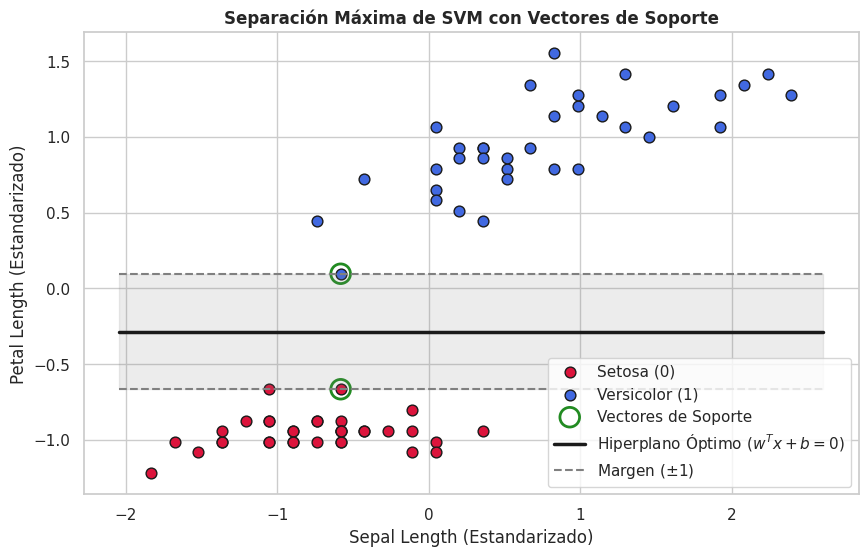

In [70]:
plt.figure(figsize=(10, 6))

# Datos de entrenamiento
plt.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1], color='crimson', label='Setosa (0)', s=60, edgecolors='k')
plt.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1], color='royalblue', label='Versicolor (1)', s=60, edgecolors='k')

# Marcamos los vectores de soporte con círculos verdes
plt.scatter(
    vectores_soporte[:, 0], vectores_soporte[:, 1],
    s=200, facecolors='none', edgecolors='forestgreen', linewidths=2,
    label='Vectores de Soporte'
)

# Generamos puntos en X1 para calcular las rectas
ax = plt.gca()
x1_puntos = np.linspace(ax.get_xlim()[0], ax.get_xlim()[1], 200)

# Despejamos x2 de la ecuación w1*x1 + w2*x2 + b = valor
x2_hiperplano = (-w[0] * x1_puntos - b) / w[1]
x2_margen_sup = (-w[0] * x1_puntos - b + 1.0) / w[1]
x2_margen_inf = (-w[0] * x1_puntos - b - 1.0) / w[1]

# Dibujamos las líneas
plt.plot(x1_puntos, x2_hiperplano, 'k-', linewidth=2.5, label='Hiperplano Óptimo ($w^T x + b = 0$)')
plt.plot(x1_puntos, x2_margen_sup, 'k--', linewidth=1.5, color='gray', label='Margen ($\pm 1$)')
plt.plot(x1_puntos, x2_margen_inf, 'k--', linewidth=1.5, color='gray')

# Sombras del margen
plt.fill_between(x1_puntos, x2_margen_inf, x2_margen_sup, color='gray', alpha=0.15)

plt.title('Separación Máxima de SVM con Vectores de Soporte', fontsize=12, fontweight='bold')
plt.xlabel('Sepal Length (Estandarizado)')
plt.ylabel('Petal Length (Estandarizado)')
plt.legend(loc='lower right')
plt.show()

<h3><strong>Evaluación de las Métricas</strong></h3>

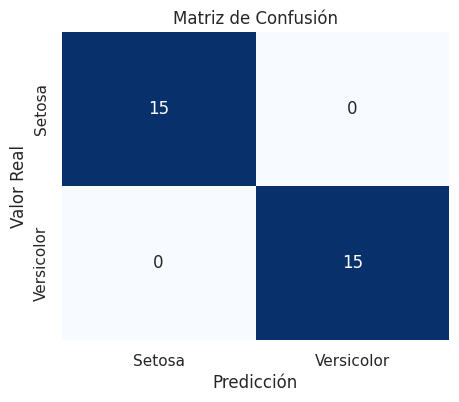


=== Reporte de Evaluación ===
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        15
  Versicolor       1.00      1.00      1.00        15

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Exactitud (Accuracy): 100.00%


In [71]:
# Realizamos las predicciones sobre el conjunto de prueba
y_pred = modelo_svm.predict(X_test)

# Matriz de Confusión
plt.figure(figsize=(5, 4))
sns.heatmap(
    confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False,
    xticklabels=['Setosa', 'Versicolor'], yticklabels=['Setosa', 'Versicolor']
)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()

# Reporte formal de métricas
print("\n=== Reporte de Evaluación ===")
print(classification_report(y_test, y_pred, target_names=['Setosa', 'Versicolor']))
print(f"Exactitud (Accuracy): {accuracy_score(y_test, y_pred) * 100:.2f}%")

<h3><strong>Predicciones</strong></h3>

In [72]:
# Nuevas flores medidas manualmente en el campo (en cm)
nuevas_flores_cm = np.array([
    [4.8, 1.4],  # Flor 1: Sepal=4.8, Petal=1.4 (Debería ser Setosa)
    [6.2, 4.5]   # Flor 2: Sepal=6.2, Petal=4.5 (Debería ser Versicolor)
])

# 1. Aplicamos el MISMO escalado Z-score usado en el entrenamiento
nuevas_flores_scaled = escalador.transform(nuevas_flores_cm)

# 2. El modelo emite la predicción
predicciones = modelo_svm.predict(nuevas_flores_scaled)

# 3. Mapeamos los números a nombres entendibles
nombres = {0: 'Iris-setosa', 1: 'Iris-versicolor'}

print("=== Predicción para Nuevas Muestras ===")
for i, (cm, pred) in enumerate(zip(nuevas_flores_cm, predicciones)):
    print(f"Muestra #{i+1} con medidas {cm} cm --> Clasificada como: {nombres[pred]}")

=== Predicción para Nuevas Muestras ===
Muestra #1 con medidas [4.8 1.4] cm --> Clasificada como: Iris-setosa
Muestra #2 con medidas [6.2 4.5] cm --> Clasificada como: Iris-versicolor
